**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**05 | Classical ML Baselines: HARTH Activity Classification**

![Classical machine learning baselines workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/05_workflow.svg)

**Objective:** Compare Dummy, Logistic Regression and Random Forest classifiers using participant-disjoint Train and Validation data from eight HARTH recordings.

**Dataset:** Eight selected participants from the pinned HARTH v2.0 release, using label-pure, two-second accelerometer windows and 30 statistical features.

**Notebook Scope:** Evaluate eight documented activity codes (1–8) on Validation only, inspect class-specific errors and retain the exploratory Test partition without scoring it. Other source labels are excluded after windowing and reported separately. This pilot is not the later full Development benchmark.

**00. Colab Repository Setup**

In [ ]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Environment**

In [2]:
# ======================== 01. Imports and Environment ========================

# ---------------------------- 1. Standard Library ----------------------------
import sys
from pathlib import Path

# --------------------- 2. Repository Path Configuration ----------------------
root = Path.cwd().resolve()
while not (root / "python_modules/core/data_loading.py").is_file():
    if root == root.parent:
        raise RuntimeError("Open this notebook from inside human-movement-intelligence.")
    root = root.parent
sys.path.insert(0, str(root / "python_modules"))
sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10, 
    figure_dpi=100, figure_size=(9, 4))

# -------------------- 5. Machine Learning Evaluation Tools -------------------
from sklearn.metrics import ConfusionMatrixDisplay

# ----------------------- 6. Shared and Study Utilities -----------------------
from core.output_download import download_outputs_from_colab
from harth_data import ACTIVITY_NAMES, ensure_harth_sample, load_harth_subject
from core.signal_preprocessing import create_signal_windows
from core.feature_engineering import extract_signal_features
from core.data_splitting import split_group_indices
from core.ml_baselines import (
    train_validation_classifiers, classification_class_report,
    classification_confusion,
)

# -------------------- 7. Output Directory and Setup Summary ------------------
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Shared ML utilities imported successfully")
print("Research output directory:", output_dir)

Shared ML utilities imported successfully
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output


**02. Prepare Source Features from Eight HARTH Participants**

Use the same participant list, two-second windowing protocol and deterministic features as Notebook 04. Preserve undocumented source codes for the label audit before restricting the classification task.

In [3]:
# =============== 02. Prepare Source Features from Eight People ===============

# -------------------- 1. Cohort and Source Configuration ---------------------
SUBJECTS = ["S023", "S024", "S025", "S027", "S028", "S032", "S034", "S035"]
TASK_CLASSES = tuple(range(1, 9))
DATA_ROOT = root / "data/raw/harth_v2"
feature_parts, metadata_parts = [], []

# ------------------- 2. Per-Participant Feature Extraction -------------------
for subject in SUBJECTS:
    source_path = ensure_harth_sample(DATA_ROOT, subject=subject)
    data, channels = load_harth_subject(
        source_path, allow_unmapped_labels=True  # Retain undocumented source codes for auditing.
    )
    windows, labels, info = create_signal_windows(
        signals=data[channels].to_numpy(),
        labels=data["label"].to_numpy(),
        window_size=100, step_size=50,
        timestamps=data["timestamp"], sampling_rate=50,
        min_label_purity=1.0, subject_id=subject,  # Reject windows with mixed activity labels.
    )
    feature_parts.append(extract_signal_features(windows, channel_names=channels))
    metadata_parts.append(info)

# ---------------------- 3. Combine and Validate Results ----------------------
features_all = pd.concat(feature_parts, ignore_index=True)
metadata_all = pd.concat(metadata_parts, ignore_index=True)
assert len(features_all) == len(metadata_all)

print("Complete source feature matrix:", features_all.shape)


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S023.csv
HARTH subject S023: 137,646 rows, 6 sensors
Input signal: 137,646 samples, 6 channels
Candidate windows: 2,751
Retained windows: 2,567 | Shape: (2567, 6, 100)
Rejected candidates: 184
Input windows: (2567, 6, 100)
Feature matrix: (2567, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S024.csv
HARTH subject S024: 170,534 rows, 6 sensors
Input signal: 170,534 samples, 6 channels
Candidate windows: 3,409
Retained windows: 3,119 | Shape: (3119, 6, 100)
Rejected candidates: 290
Input windows: (3119, 6, 100)
Feature matrix: (3119, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S025.csv
HARTH subject S025: 231,729 rows, 6 sensors
Input signal: 231,729 samples, 6 channels
Candidate windows: 4,633
Retained windows: 4,272 | 

/tmp/ipykernel_8959/33843195.py:12: UserWarning: Unexpected HARTH activity codes: [10, 11] (2,018 rows in S032.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S032: 178,341 rows, 6 sensors
Input signal: 178,341 samples, 6 channels
Candidate windows: 3,565
Retained windows: 3,038 | Shape: (3038, 6, 100)
Rejected candidates: 527
Input windows: (3038, 6, 100)
Feature matrix: (3038, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Input windows: (3351, 6, 100)
Feature matrix: (3351, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 287
Input windows: (3337, 6, 100)
Feature matr

**03. Restrict the Cohort to Eight Documented Activities**

Retain published HARTH codes 1–8 after time-safe windowing. Report excluded codes and participant-level support without joining otherwise separate source intervals.

In [4]:
# ============== 03. Restrict to the Documented Eight-Class Task ==============

# ------------------ 1. Audit Source Labels and Select Task -------------------
raw_class_counts = (
    metadata_all.groupby(["subject_id", "label"])
    .size().rename("windows").reset_index()
)

raw_class_counts["activity"] = raw_class_counts["label"].map(
    lambda value: ACTIVITY_NAMES.get(int(value), "UNDOCUMENTED")
)

raw_class_counts["in_task"] = raw_class_counts["label"].isin(TASK_CLASSES)

display(raw_class_counts)
raw_class_counts.to_csv(output_dir / "05_source_label_audit.csv", index=False)
included = metadata_all["label"].isin(TASK_CLASSES).to_numpy()  # Filter only after constructing time-safe windows.

# ------------------ 2. Report Exclusions and Align Features ------------------
excluded = metadata_all.loc[~included, "label"].value_counts().sort_index()
features = features_all.loc[included].reset_index(drop=True)
metadata = metadata_all.loc[included].reset_index(drop=True)

print("Excluded windows by source code:", excluded.to_dict())
print("Eight-class feature matrix:", features.shape)


,subject_id,label,windows,activity,in_task
0,S023,1,1352,Walking,True
1,S023,2,441,Running,True
2,S023,3,7,Shuffling,True
3,S023,4,42,Stairs ascending,True
4,S023,5,26,Stairs descending,True
5,S023,6,114,Standing,True
6,S023,7,257,Sitting,True
7,S023,8,328,Lying,True
8,S024,1,1492,Walking,True
9,S024,2,511,Running,True


Excluded windows by source code: {10: 1, 13: 1018, 14: 238, 130: 78, 140: 65}
Eight-class feature matrix: (24563, 30)


**04. Create Participant-Disjoint Train/Validation/Test Splits**

Reproduce the fixed-seed eight-participant split from Notebook 04. Train and Validation are used for model comparison; the exploratory Test partition is reserved and not scored.

**Protocol distinction:** These groups precede the later 29-person Development protocol and qualified held-out evaluation.

In [5]:
# ================ 04. Create Subject-Disjoint Data Partitions ================

# ------------------- 1. Create Subject-Disjoint Partitions -------------------
partitions = split_group_indices(
    metadata["subject_id"].to_numpy(),
    train_fraction=0.50, validation_fraction=0.25,
    test_fraction=0.25, random_state=42,
)

# ------------------ 2. Verify Groups and Report Membership -------------------
group_sets = {
    part: set(metadata.iloc[idx]["subject_id"])
    for part, idx in partitions.items()
}

assert not (group_sets["train"] & group_sets["validation"])
assert not (group_sets["train"] & group_sets["test"])
assert not (group_sets["validation"] & group_sets["test"])
partition_summary = pd.DataFrame([
    {"partition":part,"subjects":", ".join(sorted(group_sets[part])),
     "windows":len(idx)}
    for part,idx in partitions.items()
])
display(partition_summary)
partition_summary.to_csv(output_dir / "05_exploratory_partition_membership.csv", index=False)

# ------------------ 3. Train and Validation Class Coverage -------------------
train_ids, validation_ids = partitions["train"], partitions["validation"]
X_train = features.iloc[train_ids]
y_train = metadata.iloc[train_ids]["label"].to_numpy()
X_validation = features.iloc[validation_ids]
y_validation = metadata.iloc[validation_ids]["label"].to_numpy()
coverage = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(),
    "validation": pd.Series(y_validation).value_counts(),
}).reindex(TASK_CLASSES, fill_value=0).fillna(0).astype(int)
coverage.index = [ACTIVITY_NAMES[c] for c in TASK_CLASSES]

display(coverage)
coverage.rename_axis("activity").reset_index().to_csv(
    output_dir / "05_train_validation_class_coverage.csv", index=False
)
assert (coverage["train"] > 0).all(), "Not every defined task class is in Train."

print("Held-out test partition: reserved, not inspected for modelling")


Independent groups: 8
train: 4 groups | 12,489 rows
validation: 2 groups | 6,470 rows
test: 2 groups | 5,604 rows


,partition,subjects,windows
0,train,"S025, S027, S028, S035",12489
1,validation,"S024, S034",6470
2,test,"S023, S032",5604


,train,validation
Walking,6053,2009
Running,3283,511
Shuffling,91,58
Stairs ascending,76,82
Stairs descending,54,65
Standing,700,1219
Sitting,1039,1547
Lying,1193,979


Held-out test partition: reserved, not inspected for modelling


**05. Train and Compare the Three Validation Baselines**

Compare a majority-class DummyClassifier, Train-scaled Logistic Regression and unscaled Random Forest. Use Macro F1 as the main model-selection metric, with all preprocessing fitted on Train only.

In [6]:
# ================ 05. Train and Compare Validation Baselines =================

# ------------------- 1. Fit and Compare Validation Models --------------------
models, comparison, predictions = train_validation_classifiers(
    X_train, y_train, X_validation, y_validation,
    classes=TASK_CLASSES, random_state=42,
)
display(comparison.style.format({
    name:"{:.3f}" for name in comparison.columns if name != "model"
}))
comparison.to_csv(output_dir / "05_validation_model_metrics.csv", index=False)
best_name = comparison.loc[0, "model"]

print("Best validation Macro F1:", best_name)
print("Final Test evaluated: NO")


Dummy (most frequent): Validation Macro F1 = 0.0592
Logistic Regression: Validation Macro F1 = 0.8339
Random Forest: Validation Macro F1 = 0.7597


,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,Logistic Regression,0.949,0.893,0.830,0.893,0.834
1,Random Forest,0.971,0.739,0.885,0.739,0.760
2,Dummy (most frequent),0.311,0.125,0.039,0.125,0.059


Best validation Macro F1: Logistic Regression
Final Test evaluated: NO


**06. Compare Validation Metrics Visually**

Plot Macro F1 and balanced accuracy from the same held-out Validation participants. The scores describe this exploratory split, not external or final Test performance.

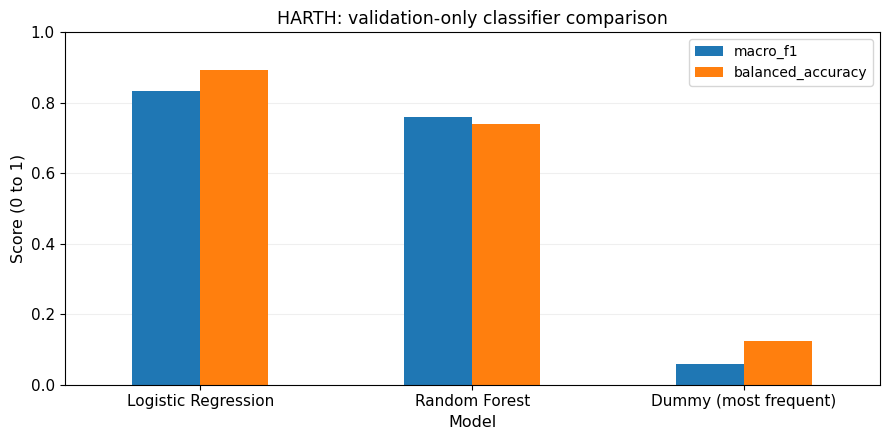

In [7]:
# ================== 06. Compare Validation Metrics Visually ==================
plot_table = comparison.set_index("model")[["macro_f1", "balanced_accuracy"]]
ax = plot_table.plot(kind="bar", figsize=(9, 4.5), rot=0)
ax.set(title="HARTH: validation-only classifier comparison",
       xlabel="Model", ylabel="Score (0 to 1)", ylim=(0, 1))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
save_figure(ax.figure, output_dir / "05_validation_model_comparison.png")
plt.show()


**07. Inspect Per-Class Errors of the Selected Validation Model**

Examine per-class precision, recall, F1 and the confusion matrix for the Validation-selected model to identify activity-specific errors.

,class,support,precision,recall,f1
0,Walking,2009,0.977898,0.902937,0.938923
1,Running,511,1.000000,0.994129,0.997056
2,Shuffling,58,0.239819,0.913793,0.379928
3,Stairs ascending,82,0.514851,0.634146,0.568306
4,Stairs descending,65,0.960784,0.753846,0.844828
5,Standing,1219,0.943441,0.985234,0.963884
6,Sitting,1547,1.000000,0.957983,0.978541
7,Lying,979,1.000000,1.000000,1.000000


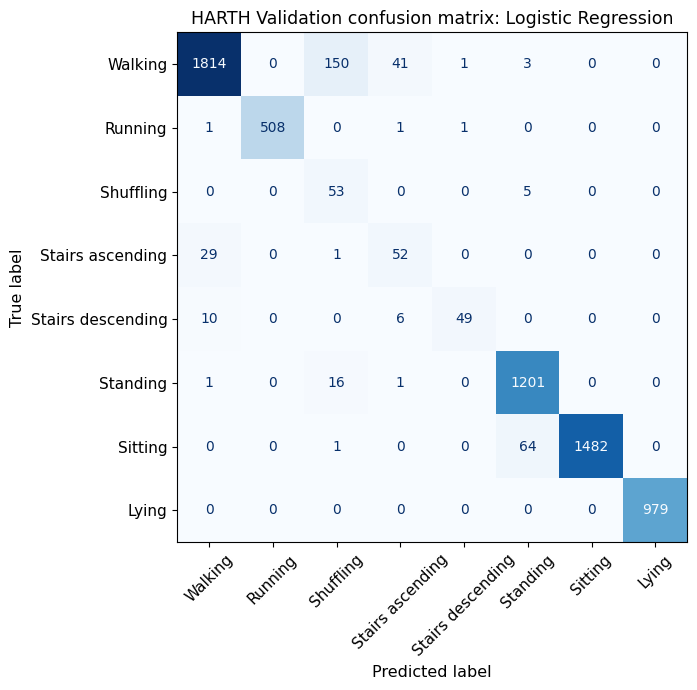

In [8]:
# ================= 07. Inspect Validation Class-Level Errors =================

# ----------------- 1. Selected Model and Class-Level Metrics -----------------
best_predictions = predictions[best_name]
class_names = [ACTIVITY_NAMES[code] for code in TASK_CLASSES]
class_report = classification_class_report(
    y_validation, best_predictions,
    classes=TASK_CLASSES, class_names=class_names,
)

display(class_report)
class_report.to_csv(output_dir / "05_selected_validation_per_class.csv", index=False)
pd.DataFrame({
    "subject_id": metadata.iloc[validation_ids]["subject_id"].to_numpy(),
    "true_source_code": y_validation,
    "predicted_source_code": best_predictions,
}).to_csv(output_dir / "05_selected_validation_predictions.csv", index=False)

# ---------------------- 2. Validation Confusion Matrix -----------------------
matrix = classification_confusion(
    y_validation, best_predictions, classes=TASK_CLASSES
)
pd.DataFrame(matrix, index=class_names, columns=class_names).rename_axis(
    "true_activity"
).to_csv(output_dir / "05_selected_validation_confusion_counts.csv")

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(
    confusion_matrix=matrix, display_labels=class_names
).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"HARTH Validation confusion matrix: {best_name}")
plt.tight_layout()
save_figure(fig, output_dir / "05_selected_validation_confusion.png")
plt.show()


**08. Exploratory Baseline Quality Gate**

Verify feature integrity, participant separation, the predefined eight-class target and the absence of Test scoring. Interpret the model comparison within this exploratory Validation protocol; the remaining HARTH participants and independent evaluation are outside its scope.


In [9]:
# =================== 08. Exploratory Baseline Quality Gate ===================

# ------------------ 1. Verify Features and Group Separation ------------------
assert X_train.shape[1] == X_validation.shape[1] == 30
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_validation.to_numpy()).all()

assert not (group_sets["train"] & group_sets["validation"])
assert len(comparison) == 3
assert comparison["macro_f1"].between(0, 1).all()
print("Train subject IDs:", sorted(group_sets["train"]))
print("Validation subject IDs:", sorted(group_sets["validation"]))

# --------------------- 2. Quality Gate and Test Boundary ---------------------
print("Defined classification task:", [ACTIVITY_NAMES[c] for c in TASK_CLASSES])
print("Undocumented/source-excluded windows:", int((~included).sum()))

print("Final Test model inference performed: NO")

print("Exploratory validation baseline: PASSED")

download_outputs_from_colab(folder="wearable_activity_recognition/output", stage="05")

Train subject IDs: ['S025', 'S027', 'S028', 'S035']
Validation subject IDs: ['S024', 'S034']
Defined classification task: ['Walking', 'Running', 'Shuffling', 'Stairs ascending', 'Stairs descending', 'Standing', 'Sitting', 'Lying']
Undocumented/source-excluded windows: 1400
Final Test model inference performed: NO
Exploratory validation baseline: PASSED
------------------------------------------------------------------------
Notebook stage: 05
Files packaged: 9
  + 05_exploratory_partition_membership.csv
  + 05_selected_validation_confusion.png
  + 05_selected_validation_confusion_counts.csv
  + 05_selected_validation_per_class.csv
  + 05_selected_validation_predictions.csv
  + 05_source_label_audit.csv
  + 05_train_validation_class_coverage.csv
  + 05_validation_model_comparison.png
  + 05_validation_model_metrics.csv
Download ZIP from Colab Contents: /content/wearable_activity_recognition_Stage_05_Outputs.zip
GitHub Commit/Push performed: NO
